# 05. Evaluasi Holdout, Interpretasi, dan Ekspor

Menguji model pada holdout test set, confusion matrix, analisis faktor, dan ekspor model untuk Streamlit.

**Prasyarat:** Tahap 01, 02, dan 04 selesai.

**Keluaran:** Laporan evaluasi, artefak pipeline terpilih, schema, dan metadata.

Pilih kernel Python 3.12 dengan dependency proyek, lalu **Restart Kernel → Run All**. Tahap 01–05 dijalankan secara berurutan. Proyek edukasi data science, bukan diagnosis medis klinis.


## A. Inisialisasi Lingkungan dan Lokasi Proyek
Mempersiapkan konstanta fitur dan folder kerja.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime, timezone
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'Dataset/Data_Asli/nhanes_depression_raw.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Buka notebook dari dalam folder proyek lengkap dengan Dataset.')
TARGET = "Depression"
LABELS = ["Not Depressed", "Depressed"]
DISPLAY = {
    "Not Depressed": "Tidak Terindikasi Depresi Mayor",
    "Depressed": "Berisiko Mengalami Depresi (PHQ-9 ≥ 10)"
}

CATEGORICAL = [
    "Gender", "Education Level", "Marital Status", "Household Income",
    "Trouble Sleeping History", "Vigorous Recreation", "Moderate Recreation",
    "Current Smoker", "Memory Problems", "Cant Work", "Limited Work"
]
NUMERIC = [
    "Age", "Sleep Hours", "Sedentary Time", "BMI", "Systolic", "Diastolic", "Pulse"
]
FEATURES = CATEGORICAL + NUMERIC

RANGES = {
    "Age": (18, 120),
    "Sleep Hours": (1.0, 24.0),
    "Sedentary Time": (0.0, 1440.0),
    "BMI": (10.0, 90.0),
    "Systolic": (60.0, 260.0),
    "Diastolic": (30.0, 160.0),
    "Pulse": (30.0, 220.0),
}

SEED = 42
REPORTS = ROOT / "Source_Code/reports"
EDA = REPORTS / "eda"
MODELING = REPORTS / "modeling"
ANALYSIS = REPORTS / "analysis"
PROCESSED = ROOT / "Dataset/Data_Olahan"
MODELS = ROOT / "Model"


for folder in [EDA, MODELING, ANALYSIS, PROCESSED, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
source = ROOT / 'Dataset/Data_Asli/nhanes_depression_raw.csv'
def save_json(path, value):
    path.write_text(
        json.dumps(value, indent=2, ensure_ascii=False,
                   default=lambda x: x.item() if isinstance(x, np.generic) else str(x)),
        encoding="utf-8"
    )

def save_figure(path):
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches='tight')
    display(Image(filename=str(path)))
    plt.close()

print('Proyek:', ROOT)


Proyek: D:\KULIAH\sem-5\MACHINE LEARNING\PJBL\prediksi_gangguan_depresi


## B. Memuat State Pelatihan dari Tahap 04
Memuat model lokal dan memverifikasi integritas hash.


In [2]:
split_file = PROCESSED / 'notebook_split.json'
if not split_file.exists():
    raise FileNotFoundError('Jalankan 01_persiapan_data.ipynb terlebih dahulu.')
split_state = json.loads(split_file.read_text(encoding='utf-8'))
for relative, expected in split_state['input_hashes'].items():
    if hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() != expected:
        raise ValueError('Data berubah. Jalankan ulang notebook 01: ' + relative)
raw = pd.read_csv(source, low_memory=False)
saved_clean = pd.read_csv(PROCESSED / 'cleaned.csv', low_memory=False)
clean = saved_clean[FEATURES + [TARGET]].copy()
ids = saved_clean['source_seqn']
profile_hashes = saved_clean['profile_hash'] if 'profile_hash' in saved_clean.columns else pd.util.hash_pandas_object(clean[FEATURES], index=False).astype(str)
conflict_hashes = set()
duplicate_mask = pd.Series([False] * len(raw))
X, y = clean[FEATURES], clean[TARGET]
train_idx, test_idx = split_state['train_indices'], split_state['test_indices']
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print('Data Latih:', X_train.shape, '| Data Uji:', X_test.shape)
state_file = MODELING / 'training_notebook_state.json'
if not state_file.exists():
    raise FileNotFoundError('Jalankan 04_training_model.ipynb terlebih dahulu.')
state = json.loads(state_file.read_text(encoding='utf-8'))
rows, selection = state['rows'], state['selection']
fitted = {}
for name in state['pipeline_hashes']:
    fitted[name] = joblib.load(MODELS / f'{name}_pipeline.joblib')
summary = json.loads((EDA / 'summary.json').read_text(encoding='utf-8'))
print('Model Terpilih dari CV:', selection)


Data Latih: (29007, 18) | Data Uji: (7252, 18)


Model Terpilih dari CV: random_forest


## C. Baseline Dummy dan Fungsi Metrik
Menghitung metrik perbandingan.


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def make_preprocessor():
    """Membangun objek ColumnTransformer baru yang belum di-fit."""
    num_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])
    cat_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("numeric", num_pipeline, NUMERIC),
        ("categorical", cat_pipeline, CATEGORICAL)
    ])

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
from sklearn.inspection import permutation_importance

def metrics(y, prediction):
    return {
        "accuracy": accuracy_score(y, prediction),
        "precision_macro": precision_score(y, prediction, labels=LABELS, average="macro", zero_division=0),
        "recall_macro": recall_score(y, prediction, labels=LABELS, average="macro", zero_division=0),
        "f1_macro": f1_score(y, prediction, labels=LABELS, average="macro", zero_division=0)
    }

dummy = Pipeline([("preprocess", make_preprocessor()), ("model", DummyClassifier(strategy="most_frequent"))])
dummy.fit(X_train, y_train)
save_json(MODELING / "dummy_baseline.json", metrics(y_test, dummy.predict(X_test)))

# Evaluasi Holdout Test Set


## D. Evaluasi Ketiga Model pada Data Uji Holdout
Confusion matrix dan classification report.


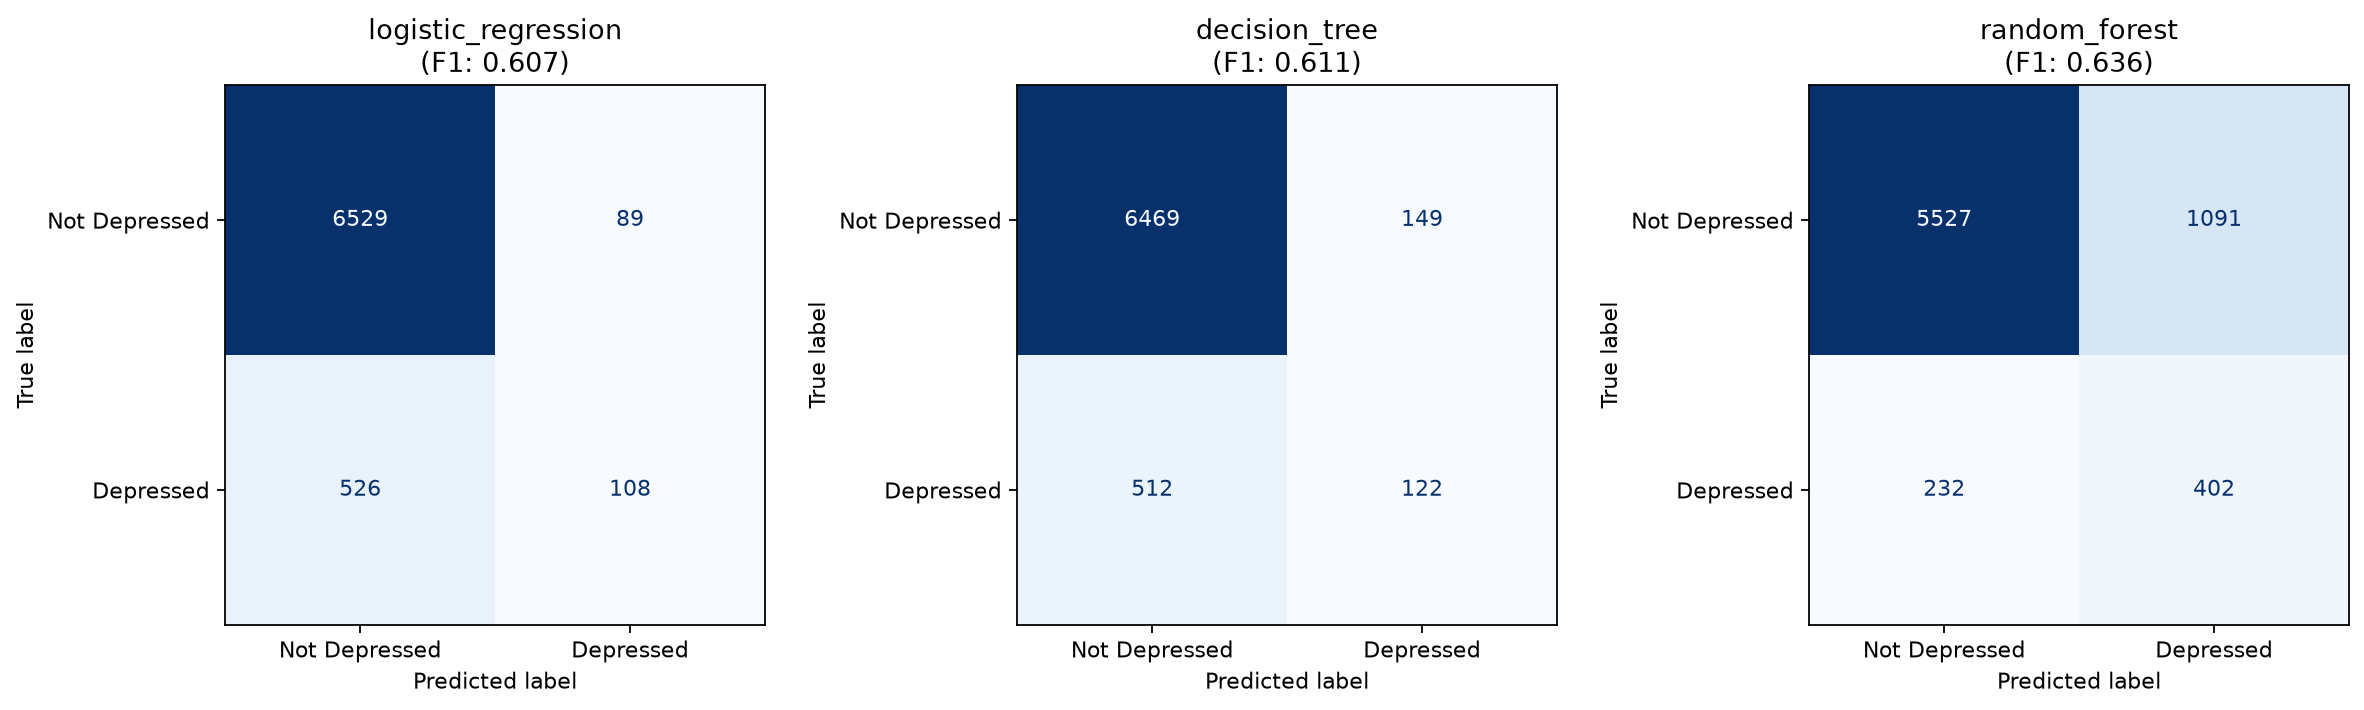

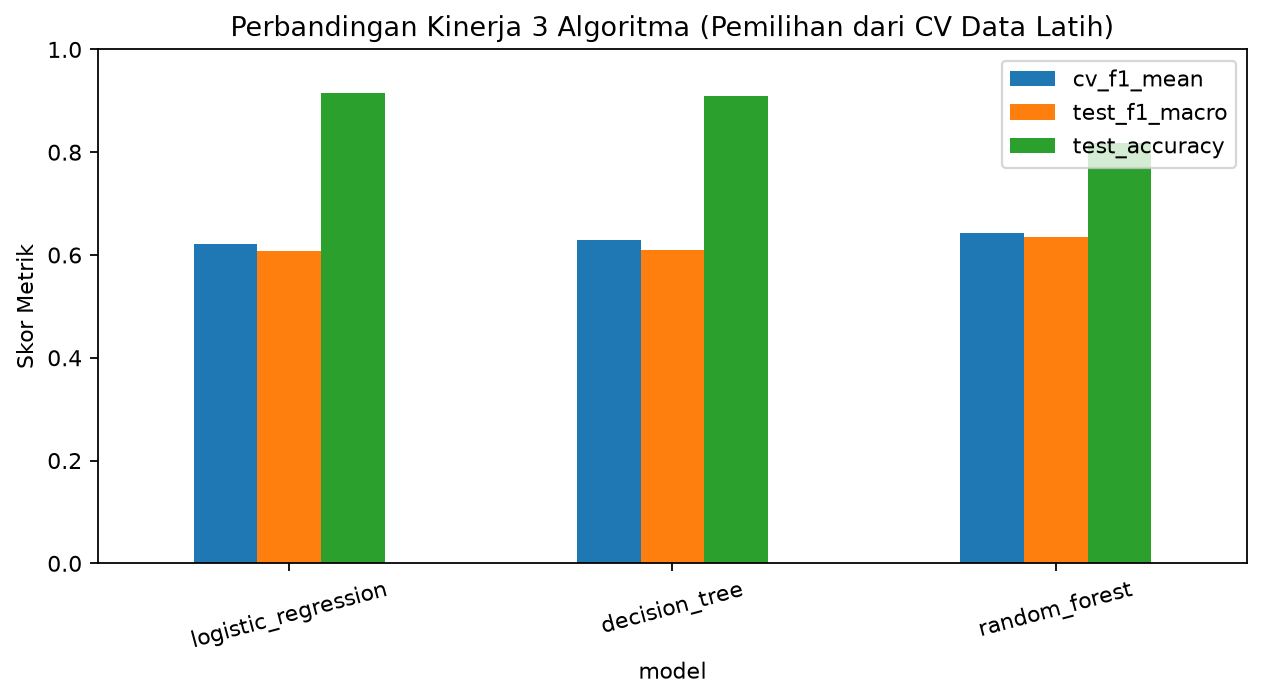

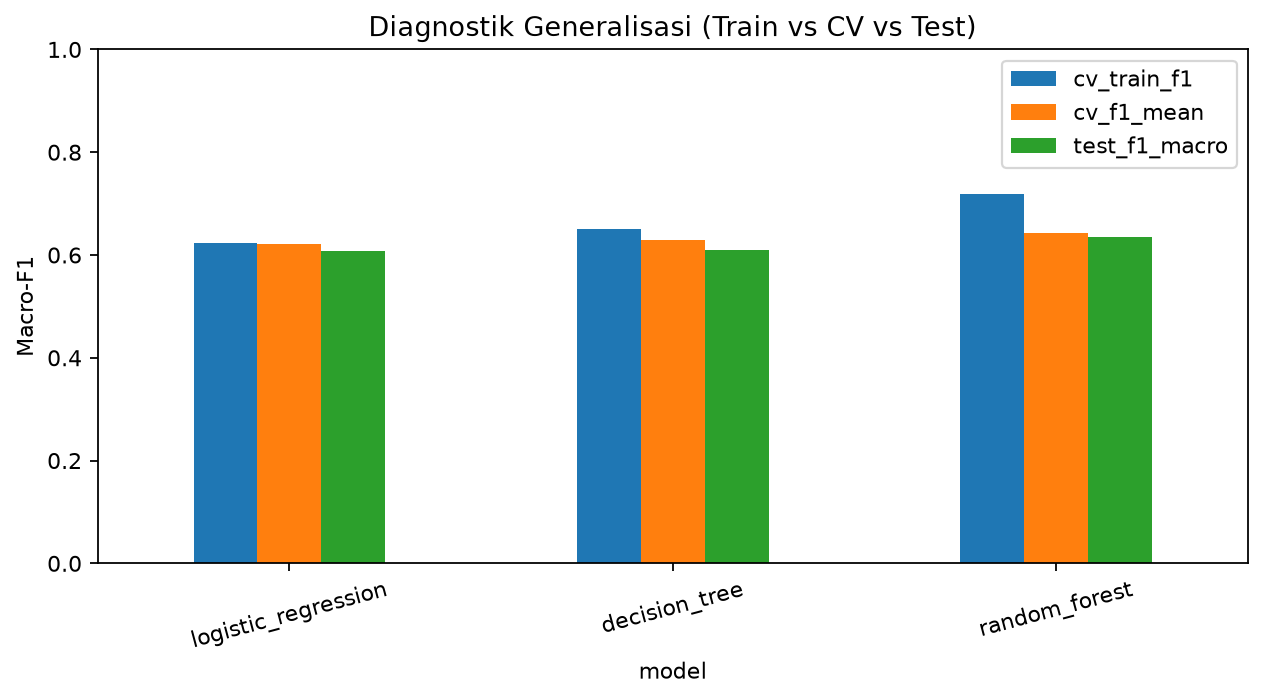

,model,baseline_cv_f1,cv_f1_mean,cv_f1_std,cv_train_f1,best_params,train_accuracy,train_precision_macro,train_recall_macro,train_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,selected_by_cv,train_cv_gap
0,logistic_regression,0.621636,0.621636,0.003684,0.622393,"{""model__C"": 1.0, ""model__class_weight"": null}",0.918365,0.766218,0.588246,0.621940,0.915196,0.736833,0.578449,0.607474,False,0.000757
1,decision_tree,0.587510,0.629851,0.013954,0.651455,"{""model__class_weight"": null, ""model__max_dept...",0.920123,0.766906,0.618829,0.657171,0.908853,0.688421,0.584957,0.610503,False,0.021604
2,random_forest,0.603358,0.642809,0.007402,0.718279,"{""model__class_weight"": ""balanced"", ""model__ma...",0.854656,0.663614,0.821522,0.699875,0.817568,0.614486,0.734608,0.635553,True,0.075470


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, row in zip(axes, rows):
    name = row["model"]
    estimator = fitted[name]
    pred_test = estimator.predict(X_test)
    pred_train = estimator.predict(X_train)

    row.update({"train_" + k: v for k, v in metrics(y_train, pred_train).items()})
    row.update({"test_" + k: v for k, v in metrics(y_test, pred_test).items()})
    row["selected_by_cv"] = (name == selection)
    row["train_cv_gap"] = float(row["cv_train_f1"] - row["cv_f1_mean"])

    save_json(
        MODELING / f"classification_report_{name}.json",
        classification_report(y_test, pred_test, labels=LABELS, output_dict=True, zero_division=0)
    )

    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred_test, labels=LABELS), display_labels=LABELS
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\n(F1: {row['test_f1_macro']:.3f})")

    probs = estimator.predict_proba(X_test)
    records = X_test.copy().assign(
        clean_index=X_test.index,
        actual=y_test,
        predicted=pred_test,
        correct=(y_test.to_numpy() == pred_test)
    )
    for j, label in enumerate(estimator.classes_):
        records[f"probability_{label}"] = probs[:, j]
    records.to_csv(MODELING / f"predictions_{name}.csv", index=False)
    records.loc[~records.correct].to_csv(MODELING / f"errors_{name}.csv", index=False)

save_figure(MODELING / "01_confusion_matrices.png")

results = pd.DataFrame(rows)
results.to_csv(MODELING / "model_comparison.csv", index=False)

# Visualisasi Perbandingan Model
results.set_index("model")[["cv_f1_mean", "test_f1_macro", "test_accuracy"]].plot.bar(
    figsize=(8, 4.5), ylim=(0, 1), rot=15
)
plt.ylabel("Skor Metrik")
plt.title("Perbandingan Kinerja 3 Algoritma (Pemilihan dari CV Data Latih)")
save_figure(MODELING / "02_model_comparison.png")

results.set_index("model")[["cv_train_f1", "cv_f1_mean", "test_f1_macro"]].plot.bar(
    figsize=(8, 4.5), ylim=(0, 1), rot=15
)
plt.ylabel("Macro-F1")
plt.title("Diagnostik Generalisasi (Train vs CV vs Test)")
save_figure(ANALYSIS / "01_generalization.png")
display(results)


## E. Interpretasi Fitur (Permutation Importance & Koefisien Logit)
Mengetahui faktor-faktor yang paling mempengaruhi prediksi.


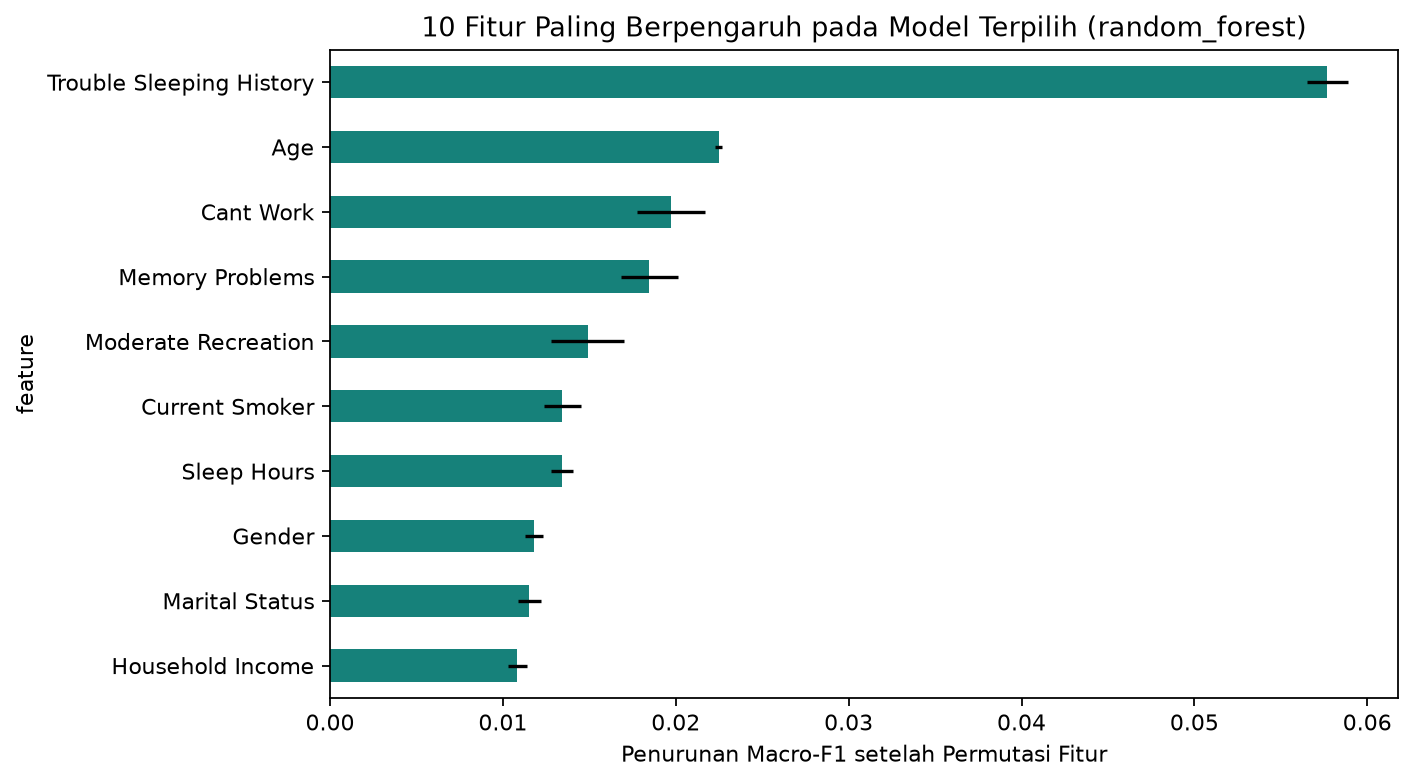

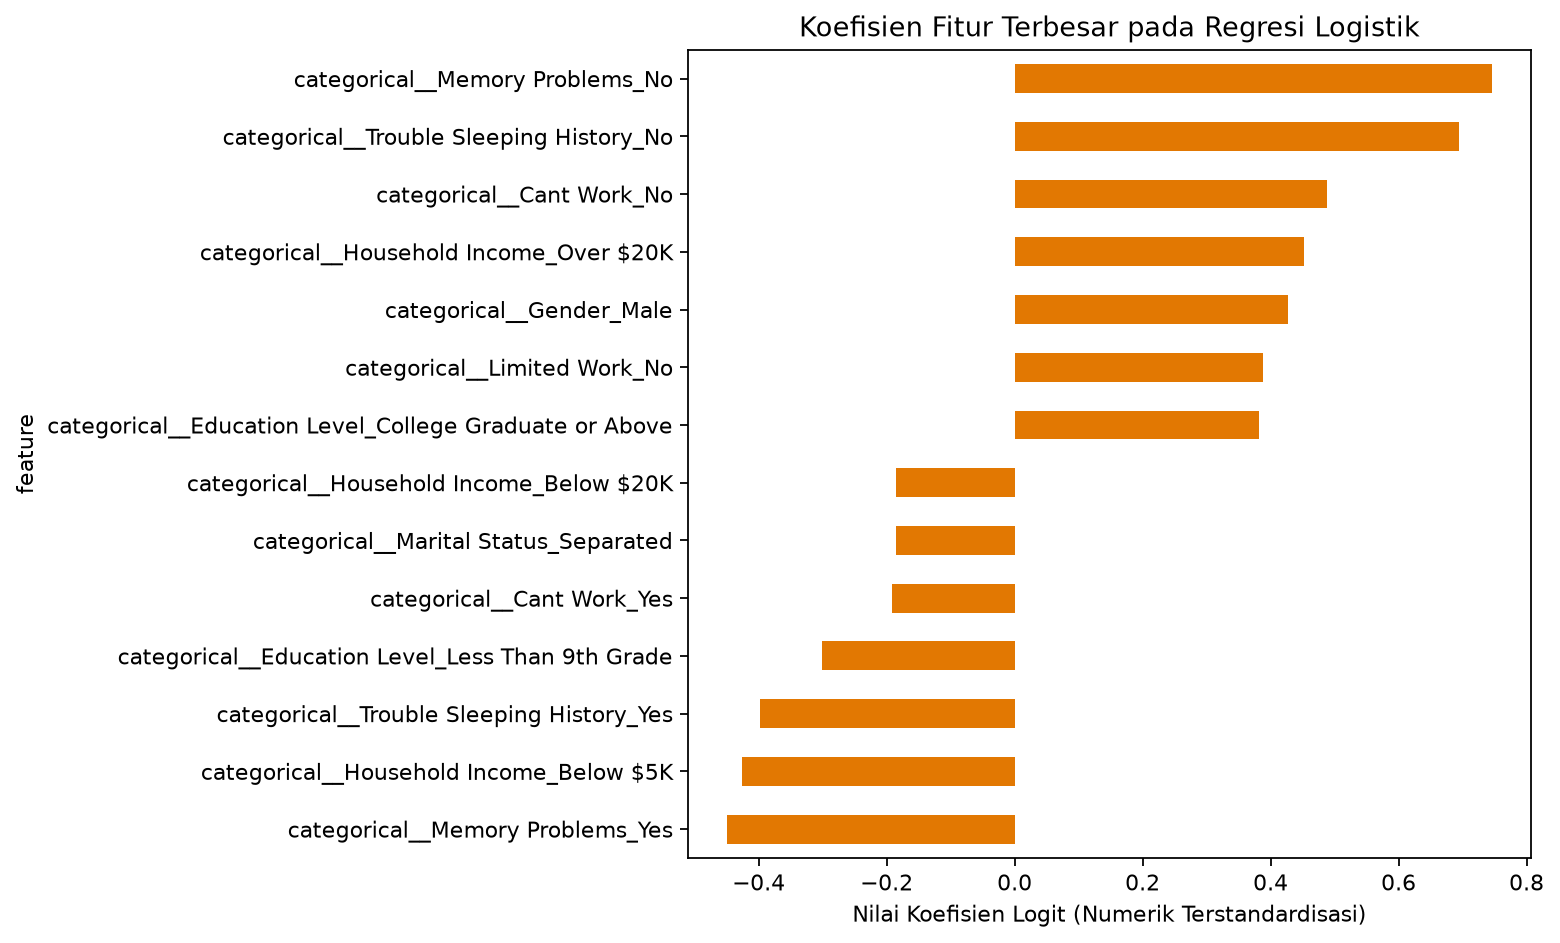

,feature,importance_mean,importance_std
4,Trouble Sleeping History,0.057675,0.001186
11,Age,0.022496,0.000206
9,Cant Work,0.019709,0.001961
8,Memory Problems,0.018477,0.001627
6,Moderate Recreation,0.014896,0.002089
7,Current Smoker,0.013439,0.001085
12,Sleep Hours,0.013422,0.000646
0,Gender,0.011803,0.000511
2,Marital Status,0.011534,0.000663
3,Household Income,0.010821,0.000550


In [5]:
# Interpretasi Fitur (pada data latih saja)
perm = permutation_importance(fitted[selection], X_train, y_train, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
importance.to_csv(ANALYSIS / "permutation_importance_train.csv", index=False)

importance.head(10).sort_values("importance_mean").plot.barh(
    x="feature", y="importance_mean", xerr="importance_std", figsize=(9, 5), legend=False, color="#16817a"
)
plt.xlabel("Penurunan Macro-F1 setelah Permutasi Fitur")
plt.title(f"10 Fitur Paling Berpengaruh pada Model Terpilih ({selection})")
save_figure(ANALYSIS / "02_permutation_importance.png")

# Koefisien Regresi Logistik
logistic = fitted["logistic_regression"]
feature_names = logistic["preprocess"].get_feature_names_out()
coef = logistic["model"].coef_[0]
coefficients = pd.DataFrame({"feature": feature_names, "coefficient": coef}).sort_values("coefficient")
coefficients.to_csv(ANALYSIS / "logistic_coefficients.csv", index=False)

top_coef = pd.concat([coefficients.head(7), coefficients.tail(7)])
top_coef.plot.barh(x="feature", y="coefficient", figsize=(10, 6), legend=False, color="#e27802")
plt.xlabel("Nilai Koefisien Logit (Numerik Terstandardisasi)")
plt.title("Koefisien Fitur Terbesar pada Regresi Logistik")
save_figure(ANALYSIS / "03_logistic_coefficients.png")
display(importance.head(10))


## F. Ekspor Pipeline Terpilih, Skema Input, dan Metadata
Menyimpan artefak final untuk aplikasi Streamlit.


In [6]:
def write_analysis(metadata, results, importance):
    s = metadata["summary"]
    chosen = results.loc[results.model == metadata["selected_model"]].iloc[0]
    lines = [
        "# Hasil Eksperimen dan Analisis Model Prediksi Gangguan Depresi",
        "",
        "Seluruh metrik dan visualisasi dihasilkan secara riil oleh eksekusi kode eksperimen proyek.",
        "",
        "## Ringkasan Data",
        f"- Data asli: {s['raw_rows']} responden, {s['raw_columns']} kolom awal.",
        f"- Setelah seleksi fitur klinis terarah dan pemeriksaan integritas: {s['clean_rows']} baris lengkap dengan {s['unique_profiles']} profil independen.",
        f"- Pembagian data: {s['train_rows']} baris data latih (80%) dan {s['test_rows']} baris data uji holdout (20%) secara berstrata.",
        "- Evaluasi tuning dilakukan via 5-Fold Stratified Cross-Validation pada data latih saja.",
        "",
        "## Perbandingan Tiga Model Machine Learning",
        "| Model | CV Macro-F1 ± SD | Train Macro-F1 | Test Accuracy | Test Precision Macro | Test Recall Macro | Test Macro-F1 |",
        "|---|---:|---:|---:|---:|---:|---:|",
    ]
    for _, r in results.iterrows():
        lines.append(
            f"| {r['model']} | {r.cv_f1_mean:.4f} ± {r.cv_f1_std:.4f} | {r.train_f1_macro:.4f} | "
            f"{r.test_accuracy:.4f} | {r.test_precision_macro:.4f} | {r.test_recall_macro:.4f} | {r.test_f1_macro:.4f} |"
        )
    lines += [
        "",
        "## Pemilihan Model",
        f"- Model terpilih untuk deployment aplikasi adalah **{chosen['model']}** dengan CV Macro-F1 tertinggi ({chosen.cv_f1_mean:.4f}).",
        "- Pilihan model dikunci sebelum data uji dievaluasi, sehingga tidak terjadi kebocoran informasi (*data leakage*).",
        "",
        "## Faktor-Faktor Paling Berpengaruh",
        "- Berdasarkan *Permutation Importance* pada data latih model terpilih:",
    ]
    for _, imp in importance.head(5).iterrows():
        lines.append(f"  - **{imp.feature}**: penurunan F1 sebesar {imp.importance_mean:.4f} ± {imp.importance_std:.4f}")
    lines += [
        "",
        "## Catatan Klinis dan Batasan",
        "- Aplikasi ini bertujuan untuk edukasi dan skrining awal, **bukan alat penegak diagnosis medis resmi**.",
        "- Label depresi berasal dari ambang batas skor kuesioner PHQ-9 (≥ 10) pada survei CDC NHANES.",
        "- Konsultasi langsung dengan psikiater atau psikolog klinis tetap menjadi rujukan utama."
    ]
    (ANALYSIS / "analisis_model.md").write_text("\n".join(lines) + "\n", encoding="utf-8")


# Simpan pipeline terpilih tanpa refit
joblib.dump(fitted[selection], MODELS / "selected_pipeline.joblib")

schema = {
    "features": FEATURES,
    "categories": {col: sorted(X_train[col].dropna().unique().tolist()) for col in CATEGORICAL},
    "training_ranges": {
        col: {
            "min": float(X_train[col].min()),
            "max": float(X_train[col].max()),
            "median": float(X_train[col].median())
        } for col in NUMERIC
    }
}
save_json(MODELS / "input_schema.json", schema)

metadata = {
    "title": "Klasifikasi Risiko Gangguan Depresi Menggunakan Algoritma Machine Learning",
    "selected_model": selection,
    "selection_rule": "Rata-rata Macro-F1 tertinggi pada 5-Fold Stratified Cross-Validation Data Latih.",
    "primary_method": "random_forest",
    "labels": LABELS,
    "summary": summary,
    "results": rows,
    "dataset_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
    "trained_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "packages": {p: importlib.metadata.version(p) for p in ["scikit-learn", "pandas", "numpy", "matplotlib", "joblib"]},
    "refit_on_test": False,
    "clinical_use": False
}
save_json(MODELS / "model_metadata.json", metadata)

# Template dan sampel input
X_test.head(5).to_csv(ROOT / "Dataset/template_input.csv", index=False)
X_test.head(10).copy().assign(actual=y_test.head(10)).to_csv(ROOT / "Dataset/contoh_prediksi.csv", index=False)

write_analysis(metadata, results, importance)
print("Selesai. Ringkasan Hasil:")
print(results[["model", "cv_f1_mean", "test_accuracy", "test_f1_macro"]].to_string(index=False))


Selesai. Ringkasan Hasil:
              model  cv_f1_mean  test_accuracy  test_f1_macro
logistic_regression    0.621636       0.915196       0.607474
      decision_tree    0.629851       0.908853       0.610503
      random_forest    0.642809       0.817568       0.635553


## G. Demonstrasi Prediksi Model Tersimpan
Menguji prediksi pada beberapa contoh profil.


In [7]:
sample = pd.read_csv(ROOT / 'Dataset/template_input.csv')
model = joblib.load(MODELS / 'selected_pipeline.joblib')
display(sample.assign(Prediksi=model.predict(sample[FEATURES])))
display(pd.DataFrame(model.predict_proba(sample[FEATURES]), columns=model.classes_))
print('Semua tahap selesai. Jalankan aplikasi Streamlit: python -m streamlit run Source_Code/app/streamlit_app.py')


,Gender,Education Level,Marital Status,Household Income,Trouble Sleeping History,Vigorous Recreation,Moderate Recreation,Current Smoker,Memory Problems,Cant Work,Limited Work,Age,Sleep Hours,Sedentary Time,BMI,Systolic,Diastolic,Pulse,Prediksi
0,Female,Missing,Missing,Below $25K,No,No,No,Missing,No,No,No,19,8.0,420.0,0.00,116.0,54.0,68.0,Not Depressed
1,Male,Some College or AA Degree,Married,Over $20K,No,Yes,No,Missing,No,No,No,53,7.0,360.0,20.93,122.0,68.0,54.0,Not Depressed
2,Male,9-11th Grade,Widowed,Below $45K,Yes,No,No,Missing,No,No,No,39,5.0,120.0,34.58,122.0,78.0,82.0,Depressed
3,Female,Less Than 9th Grade,Married,Below $10K,No,No,No,Every Day,No,No,No,28,6.0,240.0,24.53,110.0,70.0,88.0,Not Depressed
4,Female,Some College or AA Degree,Never Married,Below $55K,No,Yes,Yes,Missing,No,No,No,63,6.0,240.0,24.20,130.0,72.0,54.0,Not Depressed


,Depressed,Not Depressed
0,0.393189,0.606811
1,0.099642,0.900358
2,0.582913,0.417087
3,0.495588,0.504412
4,0.159192,0.840808


Semua tahap selesai. Jalankan aplikasi Streamlit: python -m streamlit run Source_Code/app/streamlit_app.py
